# 🧪 Lab: Write Your Own Explainable AI (XAI) Methods

**Dataset:** BloodMNIST: coloured microscope images of blood cells, 8 classes, 64 × 64 pixels  
**Model:** a small CNN (given to you)  
**Your job:** write the code for 7 XAI methods, then measure how good they are.

| Task | What you write | Marks |
|---|---|---|
| 1 | Saliency Map | 4 |
| 2 | Guided Backpropagation | 4 |
| 3 | CAM | 4 |
| 4 | Grad-CAM | 4 |
| 5 | Grad-CAM++ | 4 |
| 6 | LIME | 4 |
| 7 | SHAP | 4 |
| 8 | Side-by-side comparison figure | 2 |
| 9 | Quantitative evaluation (Deletion, Insertion, Average Drop) | 10 |
| 10 | Written questions | 10 |
| **Total** | | **50** |

### Rules
- The cells marked **GIVEN** are ready. Just run them.
- Write your code where you see `# YOUR CODE HERE`. Do not change the function names or inputs.
- Every XAI function must return a **NumPy heatmap of shape (64, 64) with values between 0 and 1**.
- After each task, run the **CHECK** cell. If it prints ✅, your output has the right shape.
- Use Google Colab with a GPU (Runtime → Change runtime type → GPU). A CPU also works, but it is slower.
- **Submit:** `RollNo_Name_XAI_Lab.ipynb` with all outputs shown.

## Part A — Setup (GIVEN)

In [1]:
!pip install -q medmnist lime shap

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 9.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 6.6 MB/s eta 0:00:00


In [2]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
import medmnist
from medmnist import INFO

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

Using: cuda


### Load BloodMNIST (GIVEN)

8 blood-cell classes: basophil, eosinophil, erythroblast, immature granulocytes, lymphocyte, monocyte, neutrophil, platelet.

100%|██████████| 156M/156M [01:40<00:00, 1.55MB/s]


11959 train | 3421 test | ['basophil', 'eosinophil', 'erythroblast', 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']


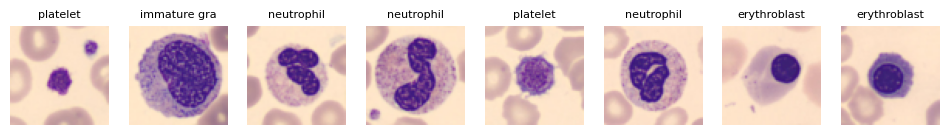

In [3]:
IMG_SIZE = 64
info = INFO["bloodmnist"]
class_names = [info["label"][str(i)] for i in range(len(info["label"]))]
num_classes = len(class_names)

transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize([0.5] * 3, [0.5] * 3)])   # pixels -> [-1, 1]

train_ds = medmnist.BloodMNIST(split="train", transform=transform, download=True, size=IMG_SIZE)
test_ds  = medmnist.BloodMNIST(split="test",  transform=transform, download=True, size=IMG_SIZE)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = torch.utils.data.DataLoader(test_ds,  batch_size=256)
print(len(train_ds), "train |", len(test_ds), "test |", class_names)

def to_image(t):
    # normalised tensor (3,H,W) -> image (H,W,3) in [0,1] for plotting
    return np.clip(t.detach().cpu().numpy().transpose(1, 2, 0) * 0.5 + 0.5, 0, 1)

plt.figure(figsize=(12, 2))
for i in range(8):
    img, lab = train_ds[i]
    plt.subplot(1, 8, i + 1); plt.imshow(to_image(img)); plt.title(class_names[int(lab[0])][:12], fontsize=8); plt.axis("off")
plt.show()

### A small CNN (GIVEN)

```
Input (3×64×64)
 → Conv 32 → ReLU → MaxPool      (32×32)
 → Conv 64 → ReLU → MaxPool      (16×16)
 → Conv 128 → ReLU               (16×16)   ← model.features  (last conv feature maps A^k)
 → Global Average Pooling        (128)
 → fc: Linear(128 → 8)                     ← model.fc  (weights w_k^c used by CAM)
```

In [4]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
        )
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(128, n_classes)

    def forward(self, x):
        return self.fc(self.gap(self.features(x)).flatten(1))

model = SimpleCNN(num_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(5):
    model.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.squeeze(1).long().to(device)
        optimizer.zero_grad()
        loss = F.cross_entropy(model(xb), yb)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch+1}  loss {loss.item():.3f}")

model.eval()
with torch.no_grad():
    correct = sum((model(xb.to(device)).argmax(1).cpu() == yb.squeeze(1)).sum().item() for xb, yb in test_loader)
print(f"Test accuracy: {100 * correct / len(test_ds):.1f}%")

epoch 1  loss 1.345
epoch 2  loss 0.862
epoch 3  loss 0.664
epoch 4  loss 0.733
epoch 5  loss 0.689
Test accuracy: 81.2%


### Pick one image and some helpers (GIVEN)

In [5]:
labels = test_ds.labels.squeeze()
idx = 0
x = test_ds[idx][0].unsqueeze(0).to(device)       # (1, 3, 64, 64)
image = to_image(x[0])
with torch.no_grad():
    probs = F.softmax(model(x), 1)[0]
pred_class = int(probs.argmax())
print("True:", class_names[labels[idx]], "| Predicted:", class_names[pred_class], f"({probs[pred_class].item():.2f})")

def normalize(a):
    a = np.asarray(a, dtype=np.float32)
    a = a - a.min()
    return a / (a.max() + 1e-8)

def upsample(t):
    # small torch map (h, w) -> numpy (64, 64) in [0, 1]
    t = torch.as_tensor(t, dtype=torch.float32).detach().cpu()
    return normalize(F.interpolate(t[None, None], size=(IMG_SIZE, IMG_SIZE), mode="bilinear")[0, 0].numpy())

def show(heat, title):
    plt.figure(figsize=(7, 2.5))
    plt.subplot(1, 3, 1); plt.imshow(image); plt.title("Image"); plt.axis("off")
    plt.subplot(1, 3, 2); plt.imshow(heat, cmap="jet"); plt.title(title); plt.axis("off")
    plt.subplot(1, 3, 3); plt.imshow(image); plt.imshow(heat, cmap="jet", alpha=0.5); plt.title("Overlay"); plt.axis("off")
    plt.show()

def check(heat, name):
    ok = isinstance(heat, np.ndarray) and heat.shape == (IMG_SIZE, IMG_SIZE) and heat.min() >= 0 and heat.max() <= 1 + 1e-6
    print(("✅ " if ok else "❌ ") + name + (" looks correct" if ok else " must return a (64, 64) numpy array in [0, 1]"))
    if ok: show(heat, name)

# Hook helper: get the feature maps A (128,16,16) and their gradients G for class `cls`
def get_A_and_G(m, x, cls):
    store = {}
    def hook(module, inp, out):
        store["A"] = out
        out.register_hook(lambda g: store.update(G=g))
    h = m.features.register_forward_hook(hook)
    m.zero_grad()
    m(x)[0, cls].backward()
    h.remove()
    return store["A"][0].detach(), store["G"][0].detach()

True: immature granulocytes(myelocytes, metamyelocytes and promyelocytes) | Predicted: immature granulocytes(myelocytes, metamyelocytes and promyelocytes) (0.54)


---
## Part B: Write the XAI methods

### Task 1: Saliency Map (4 marks)
$$\text{Saliency}(i,j) = \max_{c}\left|\frac{\partial y^{cls}}{\partial x_{c,i,j}}\right|$$
**Steps:** (1) copy `x` and make it require gradients, (2) forward pass and take the score of `cls`, (3) `backward()`, (4) take the absolute value of the input gradient, then the max over the 3 colour channels, (5) `normalize`.

✅ Saliency looks correct


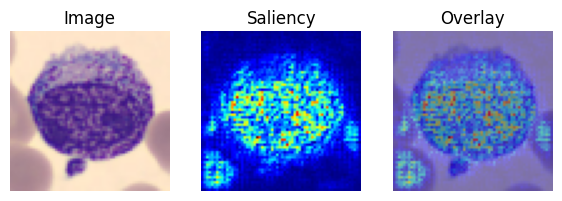

In [6]:
def saliency(m, x, cls):
    # Input-gradient saliency: max absolute gradient across RGB channels.
    m.eval()
    xi = x.detach().clone().requires_grad_(True)
    m.zero_grad(set_to_none=True)
    score = m(xi)[0, cls]
    score.backward()
    grad = xi.grad.detach().abs()[0]              # (3, H, W)
    heat = grad.max(dim=0).values.cpu().numpy()   # (H, W)
    return normalize(heat)

check(saliency(model, x, pred_class), "Saliency")

### Task 2: Guided Backpropagation (4 marks)
Like saliency, but at every ReLU only **positive** gradients may flow backwards.

**Steps:** (1) make a copy of the model with `copy.deepcopy`, (2) on every `nn.ReLU` register a **full backward hook** that returns `(torch.clamp(grad_in[0], min=0),)`, (3) compute the input gradient as in Task 1, (4) abs, max over channels, normalize.

✅ Guided Backprop looks correct


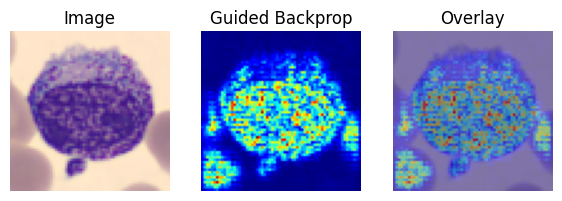

In [7]:
def guided_backprop(m, x, cls):
    # Guided Backpropagation: block negative gradients at ReLU backward passes.
    gm = copy.deepcopy(m).to(device).eval()
    hooks = []

    def guided_relu_hook(module, grad_input, grad_output):
        if grad_input[0] is None:
            return (None,)
        return (torch.clamp(grad_input[0], min=0.0),)

    for module in gm.modules():
        if isinstance(module, nn.ReLU):
            hooks.append(module.register_full_backward_hook(guided_relu_hook))

    xi = x.detach().clone().requires_grad_(True)
    gm.zero_grad(set_to_none=True)
    gm(xi)[0, cls].backward()
    grad = xi.grad.detach().abs()[0].max(dim=0).values.cpu().numpy()

    for h in hooks:
        h.remove()
    return normalize(grad)

check(guided_backprop(model, x, pred_class), "Guided Backprop")

### Task 3: CAM (4 marks)
$$\text{CAM}^{c} = \text{ReLU}\Big(\sum_k w_k^{c} A^k\Big)$$
**Steps:** (1) get `A` from `get_A_and_G`, (2) take the weights `m.fc.weight[cls]` (shape 128), (3) weighted sum over the 128 maps, (4) ReLU, (5) `upsample` to 64 × 64.

✅ CAM looks correct


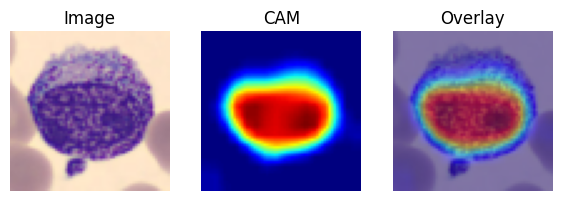

In [8]:
def cam(m, x, cls):
    # CAM uses the classifier weights because the network ends with GAP -> FC.
    m.eval()
    with torch.no_grad():
        A = m.features(x)[0]                 # (128, 16, 16)
        weights = m.fc.weight[cls]           # (128,)
        cam_map = torch.sum(weights[:, None, None] * A, dim=0)
        cam_map = F.relu(cam_map)
    return upsample(cam_map)

check(cam(model, x, pred_class), "CAM")

### Task 4: Grad-CAM (4 marks)
$$\alpha_k^c = \frac{1}{Z}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}} \qquad \text{Grad-CAM}^c = \text{ReLU}\Big(\sum_k \alpha_k^c A^k\Big)$$
**Steps:** (1) get `A, G`, (2) `alpha` = mean of `G` over height and width, (3) weighted sum, ReLU, upsample.

✅ Grad-CAM looks correct


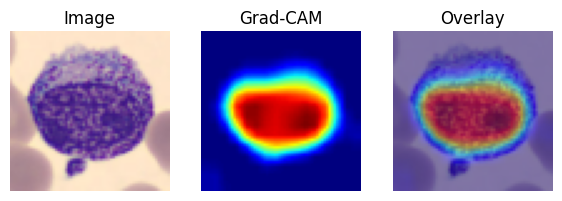

In [9]:
def grad_cam(m, x, cls):
    m.eval()
    A, G = get_A_and_G(m, x, cls)            # A,G: (128,16,16)
    alpha = G.mean(dim=(1, 2))               # (128,)
    cam_map = F.relu(torch.sum(alpha[:, None, None] * A, dim=0))
    return upsample(cam_map)

check(grad_cam(model, x, pred_class), "Grad-CAM")

### Task 5: Grad-CAM++ (4 marks)
$$a_{ij}^{k} = \frac{g_{ij}^2}{2g_{ij}^2 + \sum_{a,b}A^k_{ab}\,g_{ij}^3}\qquad w_k^c = \sum_{i,j} a^k_{ij}\,\text{ReLU}(g_{ij}) \qquad \text{Grad-CAM++}^c=\text{ReLU}\Big(\sum_k w_k^c A^k\Big)$$
(add `1e-8` to the denominator to avoid division by zero)

✅ Grad-CAM++ looks correct


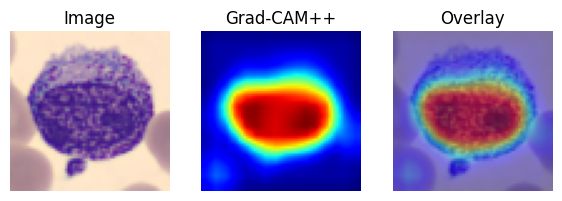

In [10]:
def grad_cam_pp(m, x, cls):
    m.eval()
    A, G = get_A_and_G(m, x, cls)

    # Per-pixel alpha coefficient for each feature map.
    G2 = G.pow(2)
    G3 = G.pow(3)
    denominator = 2.0 * G2 + (A * G3).sum(dim=(1, 2), keepdim=True)
    alpha = G2 / (denominator + 1e-8)

    # Positive gradients determine the channel weights.
    weights = (alpha * F.relu(G)).sum(dim=(1, 2))
    cam_map = F.relu(torch.sum(weights[:, None, None] * A, dim=0))
    return upsample(cam_map)

check(grad_cam_pp(model, x, pred_class), "Grad-CAM++")

### Task 6: LIME (4 marks)
**Steps:**
1. Write `predict_fn(images)`. It gets a NumPy batch `(N, 64, 64, 3)` in [0, 1] and must return class **probabilities** `(N, 8)`. Hint: apply `transform` to each image, stack them, run the model, then softmax.
2. Call `lime_image.LimeImageExplainer().explain_instance(...)` with `labels=(cls,)`, `top_labels=None`, `num_samples=500`, `segmentation_fn=segmenter`, `random_seed=0`.
3. Make a heatmap: every superpixel gets its **positive** LIME weight. Hint: `weights = dict(exp.local_exp[cls])`, and `exp.segments` tells you which superpixel each pixel belongs to.

  0%|          | 0/500 [00:00<?, ?it/s]

✅ LIME looks correct


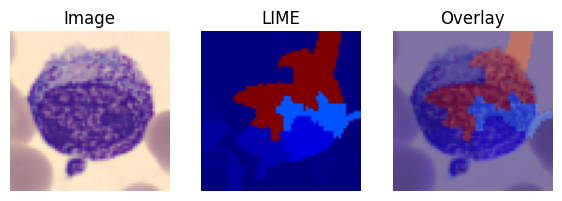

In [11]:
from lime import lime_image
from lime.wrappers.scikit_image import SegmentationAlgorithm
segmenter = SegmentationAlgorithm("slic", n_segments=50, compactness=10)

def lime_explain(m, x, cls):
    m.eval()
    img = to_image(x[0])

    def predict_fn(images):
        # LIME supplies RGB images in [0,1].
        batch = torch.stack([
            transform((np.clip(im, 0, 1) * 255).astype(np.uint8))
            for im in images
        ]).to(device)
        with torch.no_grad():
            return F.softmax(m(batch), dim=1).cpu().numpy()

    explainer = lime_image.LimeImageExplainer()
    exp = explainer.explain_instance(
        img,
        predict_fn,
        labels=(cls,),
        top_labels=None,
        num_samples=500,
        segmentation_fn=segmenter,
        random_seed=0
    )

    weights = dict(exp.local_exp[cls])
    segments = exp.segments
    heat = np.zeros_like(segments, dtype=np.float32)
    for seg_id, weight in weights.items():
        # Keep only positive contribution, as required by the task.
        heat[segments == seg_id] = max(0.0, float(weight))
    return normalize(heat)

check(lime_explain(model, x, pred_class), "LIME")

### Task 7: SHAP (4 marks)
**Steps:**
1. Make a `background` tensor from 50 training images.
2. `shap.GradientExplainer(m, background).shap_values(x, nsamples=100)`
3. Pick the values of class `cls`. **Careful:** new SHAP versions return shape `(1, 3, H, W, classes)`, older ones return a list `(classes)[1, 3, H, W]`.
4. Sum over the 3 colour channels, keep only positive values, normalize.

✅ SHAP looks correct


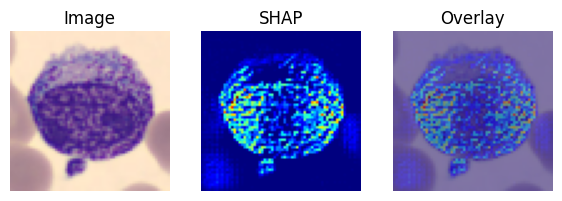

In [12]:
import shap
background = torch.stack([train_ds[i][0] for i in range(50)]).to(device)

def shap_explain(m, x, cls):
    m.eval()
    explainer = shap.GradientExplainer(m, background)
    values = explainer.shap_values(x, nsamples=100)

    # SHAP API differs across versions:
    # new: ndarray (1,3,H,W,C); old: list of C arrays (1,3,H,W).
    if isinstance(values, list):
        vals = np.asarray(values[cls])[0]           # (3,H,W)
    else:
        vals = np.asarray(values)
        if vals.ndim == 5:
            # (1,3,H,W,C)
            vals = vals[0, :, :, :, cls]
        elif vals.ndim == 4:
            # Some versions may already return (1,3,H,W).
            vals = vals[0]
        else:
            raise ValueError(f"Unexpected SHAP shape: {vals.shape}")

    # Sum RGB channels, retain positive attribution only.
    heat = np.maximum(vals.sum(axis=0), 0.0)
    return normalize(heat)

check(shap_explain(model, x, pred_class), "SHAP")

# The comparison cell below calls every method and overlays its heatmap on the image.


In [13]:
METHODS = {"Saliency": saliency, "Guided BP": guided_backprop, "CAM": cam, "Grad-CAM": grad_cam,
           "Grad-CAM++": grad_cam_pp, "LIME": lime_explain, "SHAP": shap_explain}

  0%|          | 0/500 [00:00<?, ?it/s]

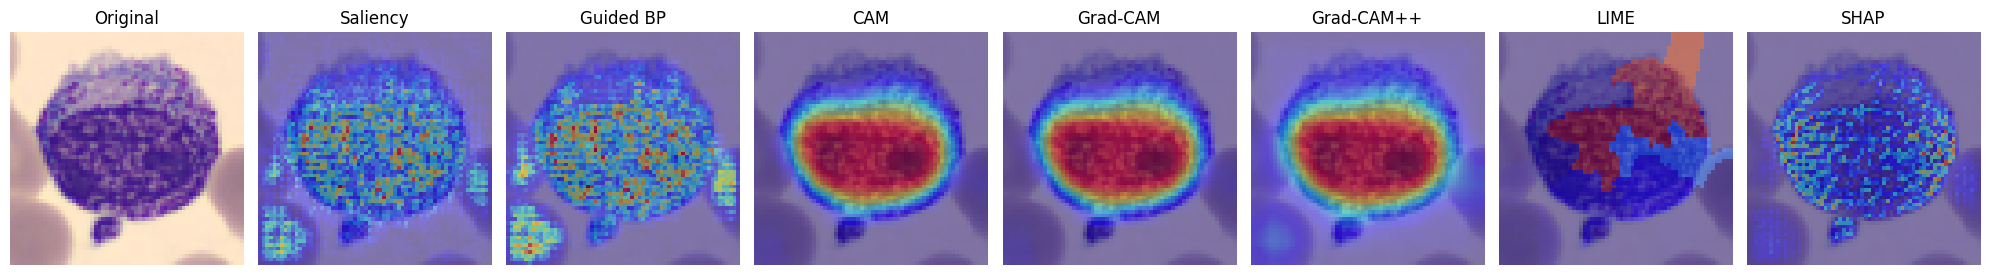

In [14]:
fig, axes = plt.subplots(1, 8, figsize=(20, 3))
axes[0].imshow(image)
axes[0].set_title("Original")
axes[0].axis("off")

for ax, (name, fn) in zip(axes[1:], METHODS.items()):
    heat = fn(model, x, pred_class)
    ax.imshow(image)
    ax.imshow(heat, cmap="jet", alpha=0.5)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

---
## Part C: Quantitative evaluation (10 marks)

### Task 9a: Deletion and Insertion AUC (4 marks)
Sort the pixels from **most** to **least** important (using the heatmap). In `steps = 20` steps:
- **Deletion:** set the top $k\%$ of pixels to 0 (the mean colour) and record the probability of `cls`. **Lower AUC is better.**
- **Insertion:** start from a **blurred** image and paste back the top $k\%$ original pixels. **Higher AUC is better.**

AUC = mean of the probabilities (trapezoid rule: `((p[:-1] + p[1:]) / 2).mean()`).  
Blur hint: `transforms.functional.gaussian_blur(x, kernel_size=15, sigma=5)`.

In [15]:
def deletion_insertion(m, x, heat, cls, steps=20):
    m.eval()
    heat = normalize(heat)
    flat_idx = np.argsort(heat.ravel())[::-1]
    n_pixels = IMG_SIZE * IMG_SIZE
    percentages = np.linspace(0, 1, steps + 1)

    # Baselines: per-channel mean colour for deletion, Gaussian blur for insertion.
    mean_colour = x.mean(dim=(2, 3), keepdim=True)
    blurred = transforms.functional.gaussian_blur(
        x, kernel_size=15, sigma=5
    )

    del_probs, ins_probs = [], []
    with torch.no_grad():
        for frac in percentages:
            k = int(round(frac * n_pixels))
            mask_np = np.zeros(n_pixels, dtype=np.float32)
            mask_np[flat_idx[:k]] = 1.0
            mask = torch.from_numpy(mask_np.reshape(1, 1, IMG_SIZE, IMG_SIZE)).to(device)

            # Deletion: replace important pixels with the mean colour.
            deleted = x * mask + mean_colour * (1.0 - mask)
            # Insertion: start blurred, then restore important pixels.
            inserted = blurred * (1.0 - mask) + x * mask

            p_del = F.softmax(m(deleted), dim=1)[0, cls].item()
            p_ins = F.softmax(m(inserted), dim=1)[0, cls].item()
            del_probs.append(p_del)
            ins_probs.append(p_ins)

    del_probs = np.asarray(del_probs)
    ins_probs = np.asarray(ins_probs)
    del_auc = np.trapezoid(del_probs, percentages)
    ins_auc = np.trapezoid(ins_probs, percentages)
    return float(del_auc), float(ins_auc)

print(deletion_insertion(model, x, grad_cam(model, x, pred_class), pred_class))

(0.34788273375281165, 0.5532961547374725)


### Task 9b: Average Drop (2 marks)
Keep only the explained region: $x' = x \odot M$ (multiply the image by the heatmap).
With $Y$ = original probability and $O$ = probability on $x'$:
$$\text{Drop} = 100\cdot\frac{\max(0, Y-O)}{Y}\qquad(\text{lower is better})$$

In [16]:
def average_drop(m, x, heat, cls):
    m.eval()
    # The heatmap is already in [0,1], so use it directly as a soft mask.
    mask = torch.as_tensor(heat, dtype=x.dtype, device=device)[None, None]
    with torch.no_grad():
        original_prob = F.softmax(m(x), dim=1)[0, cls].item()
        explained_x = x * mask
        explained_prob = F.softmax(m(explained_x), dim=1)[0, cls].item()

    if original_prob <= 1e-12:
        return 0.0
    drop = 100.0 * max(0.0, original_prob - explained_prob) / original_prob
    return float(drop)

print(average_drop(model, x, grad_cam(model, x, pred_class), pred_class))

6.40734625365306


### Task 9c: Evaluate on 20 test images (4 marks)
For 20 test images and every method: compute the heatmap for the **predicted** class, then Deletion AUC, Insertion AUC and Average Drop.
Show a table of the **mean** for each method, and a bar chart for each metric.

In [17]:
N_IMAGES = 20
rows = []

for idx_k in range(min(N_IMAGES, len(test_ds))):
    xk = test_ds[idx_k][0].unsqueeze(0).to(device)
    with torch.no_grad():
        cls = int(model(xk).argmax(dim=1).item())

    for name, fn in METHODS.items():
        heat = fn(model, xk, cls)
        del_auc, ins_auc = deletion_insertion(model, xk, heat, cls, steps=20)
        drop = average_drop(model, xk, heat, cls)
        rows.append({
            "Method": name,
            "Deletion AUC ⬇": del_auc,
            "Insertion AUC ⬆": ins_auc,
            "Avg Drop % ⬇": drop
        })

results = pd.DataFrame(rows).groupby("Method", sort=False).mean(numeric_only=True)
results

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

,Deletion AUC ⬇,Insertion AUC ⬆,Avg Drop % ⬇
Method,,,
Saliency,0.543405,0.687646,28.074050
Guided BP,0.579807,0.667411,36.431526
CAM,0.552213,0.688668,18.120694
Grad-CAM,0.552213,0.688668,18.120694
Grad-CAM++,0.581415,0.654779,44.207341
LIME,0.346094,0.678411,57.377611
SHAP,0.409791,0.763338,45.925476


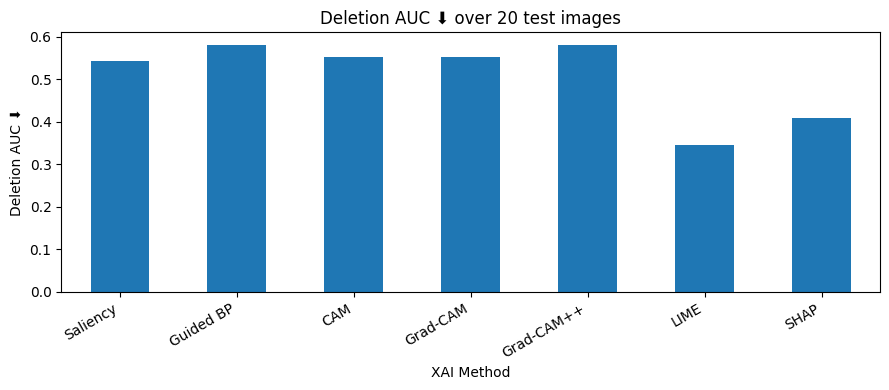

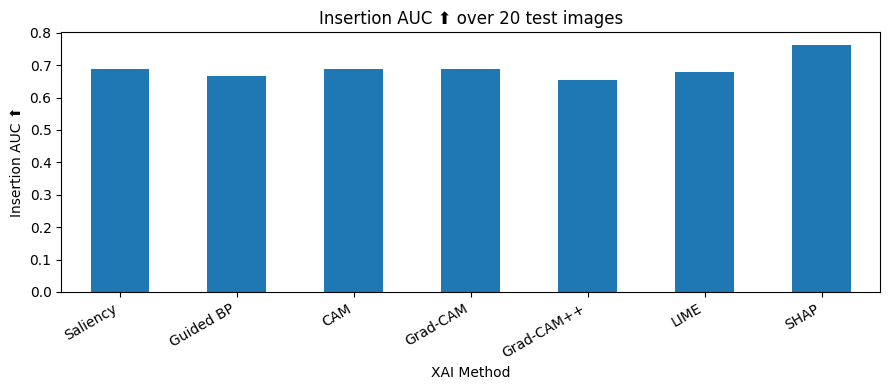

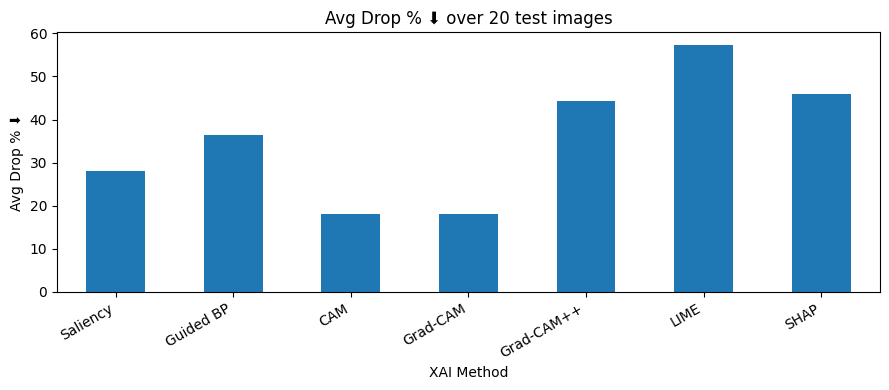

In [18]:
for metric in ["Deletion AUC ⬇", "Insertion AUC ⬆", "Avg Drop % ⬇"]:
    plt.figure(figsize=(9, 4))
    results[metric].plot(kind="bar")
    plt.ylabel(metric)
    plt.xlabel("XAI Method")
    plt.title(f"{metric} over {N_IMAGES} test images")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()